In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error
)

sns.set_theme(style="whitegrid")

## 1. Data Preparation & Preprocessing
**What I did:**
1. Loaded the Loan Prediction dataset (`loan_data.csv`), checked for missing values and duplicate rows, dropped the non-predictive `Loan_ID` identifier, and engineered `Total_Income` and `Loan_to_Income_Ratio`.
2. Checked the target class distribution (`Loan_Status`) to see if the dataset is balanced or imbalanced.
3. Split the data into 80% training and 20% testing sets using `stratify=y` and `random_state=42`.
4. Applied median imputation and `StandardScaler` to numerical features, and mode imputation and `OneHotEncoder` to categorical features inside a `ColumnTransformer` fitted strictly on the training data.

**Why:** Models require clean, numeric inputs without `NaN` values. Scaling numerical features using `StandardScaler` is essential so large-magnitude columns (like income) do not dominate distance-based algorithms like KNN. Fitting the scaler and encoder only on `X_train` prevents data leakage from the test set.

Initial Dataset Shape: (614, 13)
Duplicate rows: 0

Missing values per column:
Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64

--- Target Class Distribution (Loan_Status) ---


,Count,Percentage (%)
Loan_Status,,
Y,422,68.73
N,192,31.27


Note: The dataset is moderately imbalanced (~68.7% Approved vs ~31.3% Rejected).


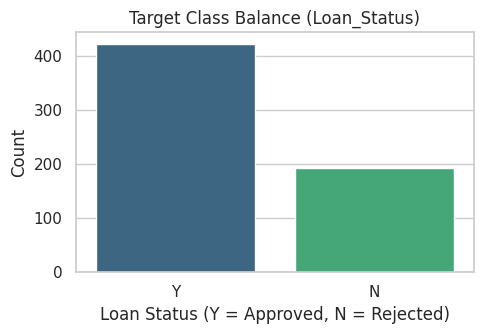


Prepared X_train shape: (491, 22) | Missing values: 0
Prepared X_test shape:  (123, 22) | Missing values: 0


In [4]:
# 1. Load data, check duplicates and missing values
df = pd.read_csv("loan_data.csv")
print("Initial Dataset Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 2. Drop identifier column and engineer domain features
if "Loan_ID" in df.columns:
    df = df.drop(columns=["Loan_ID"])

df["Total_Income"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df["Loan_to_Income_Ratio"] = df["LoanAmount"] / df["Total_Income"]

# 3. Show target class counts and check class balance
print("\n--- Target Class Distribution (Loan_Status) ---")
class_counts = df["Loan_Status"].value_counts()
class_props = df["Loan_Status"].value_counts(normalize=True) * 100
balance_df = pd.DataFrame({"Count": class_counts, "Percentage (%)": class_props.round(2)})
display(balance_df)
print("Note: The dataset is moderately imbalanced (~68.7% Approved vs ~31.3% Rejected).")

plt.figure(figsize=(5, 3.5))
sns.countplot(data=df, x="Loan_Status", hue="Loan_Status", palette="viridis", legend=False)
plt.title("Target Class Balance (Loan_Status)")
plt.xlabel("Loan Status (Y = Approved, N = Rejected)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 4. Separate features (X) and target (y)
numeric_features = [
    "ApplicantIncome", "CoapplicantIncome", "LoanAmount",
    "Loan_Amount_Term", "Credit_History", "Total_Income",
    "Loan_to_Income_Ratio"
]
categorical_features = [
    "Gender", "Married", "Dependents",
    "Education", "Self_Employed", "Property_Area"
]

X = df[numeric_features + categorical_features]
y = df["Loan_Status"].map({"Y": 1, "N": 0})

# 5. 80/20 Train/Test Split with stratify=y and random_state=42
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 6. Impute, Encode, and Scale (fit_transform on TRAIN only, transform on TEST)
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print(f"\nPrepared X_train shape: {X_train.shape} | Missing values: {np.isnan(X_train).sum()}")
print(f"Prepared X_test shape:  {X_test.shape} | Missing values: {np.isnan(X_test).sum()}")

## 2. K-Nearest Neighbors (KNN) Classifier
**What I did:** Trained a baseline `KNeighborsClassifier` with `n_neighbors=5`, then tested odd $K$ values from $1$ to $15$ ($1, 3, 5, 7, 9, 11, 13, 15$). I plotted $K$ vs. Test Accuracy and selected the optimal $K$.

**Why:** KNN classifies each applicant by taking a majority vote of the $K$ closest applicants in the scaled feature space. A very small $K$ (such as $K=1$) is overly sensitive to noise and outliers, whereas a larger odd $K$ smooths the decision boundary and avoids ties.

Baseline KNN (K=5) Test Accuracy: 0.8943

--- KNN Accuracy Across Odd K Values ---
K =  1 | Test Accuracy = 0.8374
K =  3 | Test Accuracy = 0.8537
K =  5 | Test Accuracy = 0.8943
K =  7 | Test Accuracy = 0.8699
K =  9 | Test Accuracy = 0.8618
K = 11 | Test Accuracy = 0.8862
K = 13 | Test Accuracy = 0.8618
K = 15 | Test Accuracy = 0.8537

Best K chosen: K = 5 (Test Accuracy: 0.8943)


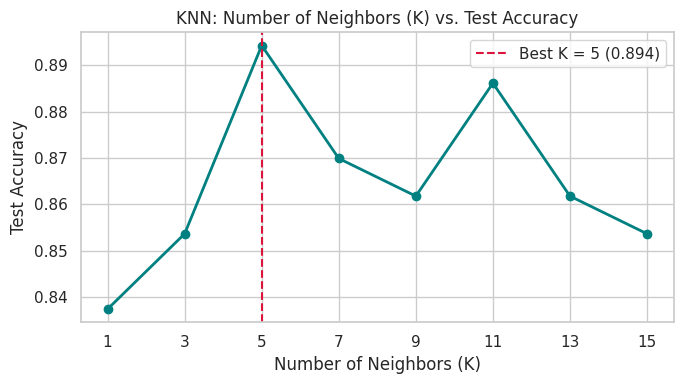

In [5]:
# 1. Train baseline KNN with n_neighbors=5
knn_5 = KNeighborsClassifier(n_neighbors=5)
knn_5.fit(X_train, y_train)
knn_5_pred = knn_5.predict(X_test)
print(f"Baseline KNN (K=5) Test Accuracy: {accuracy_score(y_test, knn_5_pred):.4f}")

# 2. Try odd K values from 1 to 15
k_values = list(range(1, 16, 2))
knn_accuracies = []

print("\n--- KNN Accuracy Across Odd K Values ---")
for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    preds = knn_temp.predict(X_test)
    acc = accuracy_score(y_test, preds)
    knn_accuracies.append(acc)
    print(f"K = {k:2d} | Test Accuracy = {acc:.4f}")

# 3. Choose the best K and plot K vs Accuracy
best_k_idx = int(np.argmax(knn_accuracies))
best_k = k_values[best_k_idx]
best_knn_acc = knn_accuracies[best_k_idx]
print(f"\nBest K chosen: K = {best_k} (Test Accuracy: {best_knn_acc:.4f})")

# Retrain final KNN model using best_k
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train, y_train)
knn_predictions = knn_best.predict(X_test)

plt.figure(figsize=(7, 4))
plt.plot(k_values, knn_accuracies, marker="o", linestyle="-", color="teal", linewidth=2)
plt.axvline(x=best_k, color="crimson", linestyle="--", label=f"Best K = {best_k} ({best_knn_acc:.3f})")
plt.title("KNN: Number of Neighbors (K) vs. Test Accuracy")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Test Accuracy")
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Decision Tree Classifier & Depth Analysis
**What I did:** Trained a `DecisionTreeClassifier` across `max_depth` values of `2, 3, 5, 10`, and `None` (unlimited depth), recording both training accuracy and testing accuracy for each setting.

**Why & What happens when the tree is very deep:** Decision trees split data using a flowchart of yes/no questions. When `max_depth=None` (or `10`), the tree grows too deep and **memorizes the training set (overfitting)**—achieving **100% training accuracy** while its **test accuracy drops significantly** because it fits noise rather than general patterns. Limiting `max_depth` (e.g., `max_depth=2` or `3`) prevents overfitting and generalizes much better to unseen test data.

--- Decision Tree: max_depth Comparison ---
max_depth = 2    | Train Accuracy = 0.8106 | Test Accuracy = 0.8780
max_depth = 3    | Train Accuracy = 0.8248 | Test Accuracy = 0.8455
max_depth = 5    | Train Accuracy = 0.8330 | Test Accuracy = 0.8699
max_depth = 10   | Train Accuracy = 0.8941 | Test Accuracy = 0.7805
max_depth = None | Train Accuracy = 1.0000 | Test Accuracy = 0.7480

Best max_depth chosen: 2 (Test Accuracy: 0.8780)


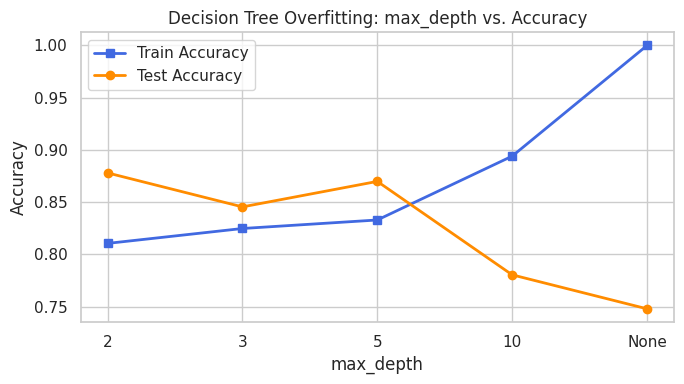

In [6]:
depths = [2, 3, 5, 10, None]
depth_labels = ["2", "3", "5", "10", "None"]
train_accs = []
test_accs = []

print("--- Decision Tree: max_depth Comparison ---")
for d, label in zip(depths, depth_labels):
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    tr_acc = accuracy_score(y_train, dt.predict(X_train))
    te_acc = accuracy_score(y_test, dt.predict(X_test))
    train_accs.append(tr_acc)
    test_accs.append(te_acc)
    print(f"max_depth = {label:4s} | Train Accuracy = {tr_acc:.4f} | Test Accuracy = {te_acc:.4f}")

best_dt_idx = int(np.argmax(test_accs))
best_depth = depths[best_dt_idx]
print(f"\nBest max_depth chosen: {best_depth} (Test Accuracy: {test_accs[best_dt_idx]:.4f})")

# Train final Decision Tree with the best max_depth
tree_model = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)

plt.figure(figsize=(7, 4))
plt.plot(depth_labels, train_accs, marker="s", label="Train Accuracy", color="royalblue", linewidth=2)
plt.plot(depth_labels, test_accs, marker="o", label="Test Accuracy", color="darkorange", linewidth=2)
plt.title("Decision Tree Overfitting: max_depth vs. Accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Logistic Regression (& Linear Regression Demonstration)
**What I did:**
1. Trained a `LogisticRegression` classifier on the prepared training set and used `predict_proba()` to inspect the predicted approval probabilities for the first 5 test applicants.
2. Trained a `LinearRegression` model to predict a continuous numerical target (`LoanAmount`) from applicant income and family features, evaluating it with Mean Absolute Error (MAE).

**Why:** Logistic Regression outputs a probability between `0` and `1` and applies a `0.5` threshold to classify categories (`Approved` vs. `Rejected`), whereas Linear Regression fits a straight line to predict a continuous number (`LoanAmount`).

In [7]:
# 1. Train Logistic Regression for Loan Approval Classification
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)
logistic_probs = logistic_model.predict_proba(X_test)

print("--- Logistic Regression: Probabilities for First 5 Test Rows ---")
prob_df = pd.DataFrame({
    "Prob_Rejected (0)": logistic_probs[:5, 0].round(4),
    "Prob_Approved (1)": logistic_probs[:5, 1].round(4),
    "Predicted_Class": logistic_predictions[:5],
    "Actual_Class": y_test.iloc[:5].values
})
display(prob_df)

# 2. Demonstrate Linear Regression (Predicting Continuous LoanAmount)
reg_features = ["ApplicantIncome", "CoapplicantIncome", "Total_Income", "Loan_Amount_Term", "Credit_History"]
df_reg = df.dropna(subset=["LoanAmount"]).copy()

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    df_reg[reg_features], df_reg["LoanAmount"], test_size=0.20, random_state=42
)

linear_reg_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearRegression()
)
linear_reg_model.fit(X_reg_train, y_reg_train)
loan_amount_preds = linear_reg_model.predict(X_reg_test)

print("\n--- Linear Regression (Predicting Continuous LoanAmount) ---")
print("First 5 Actual Loan Amounts:   ", y_reg_test.iloc[:5].values.round(1))
print("First 5 Predicted Loan Amounts:", loan_amount_preds[:5].round(1))
print(f"Mean Absolute Error (MAE):      {mean_absolute_error(y_reg_test, loan_amount_preds):.2f}")

--- Logistic Regression: Probabilities for First 5 Test Rows ---


,Prob_Rejected (0),Prob_Approved (1),Predicted_Class,Actual_Class
0,0.9418,0.0582,0,0
1,0.1065,0.8935,1,1
2,0.2435,0.7565,1,1
3,0.2833,0.7167,1,1
4,0.1000,0.9000,1,1



--- Linear Regression (Predicting Continuous LoanAmount) ---
First 5 Actual Loan Amounts:    [123.  71. 120.  87. 258.]
First 5 Predicted Loan Amounts: [124.2 116.7 129.9 134.8 161. ]
Mean Absolute Error (MAE):      36.04


## 5. Evaluate All Three Classification Models
**What I did:** Computed Accuracy, Precision, Recall, F1-score, and the full Classification Report for **KNN**, **Decision Tree**, and **Logistic Regression**. I plotted their Confusion Matrices side-by-side as heatmaps and compiled a unified comparison table.

**Why:** Comparing all four metrics alongside the confusion matrix reveals not just overall correctness (Accuracy), but how well each model balances false alarms (Precision) and missed approvals (Recall).

Model: KNN (K=5)
Accuracy: 0.8943 | Precision: 0.9000 | Recall: 0.9529 | F1: 0.9257

Classification Report:
              precision    recall  f1-score   support

Rejected (0)       0.88      0.76      0.82        38
Approved (1)       0.90      0.95      0.93        85

    accuracy                           0.89       123
   macro avg       0.89      0.86      0.87       123
weighted avg       0.89      0.89      0.89       123

Model: Decision Tree (depth=2)
Accuracy: 0.8780 | Precision: 0.8723 | Recall: 0.9647 | F1: 0.9162

Classification Report:
              precision    recall  f1-score   support

Rejected (0)       0.90      0.68      0.78        38
Approved (1)       0.87      0.96      0.92        85

    accuracy                           0.88       123
   macro avg       0.88      0.82      0.85       123
weighted avg       0.88      0.88      0.87       123

Model: Logistic Regression
Accuracy: 0.8618 | Precision: 0.8400 | Recall: 0.9882 | F1: 0.9081

Classification Report

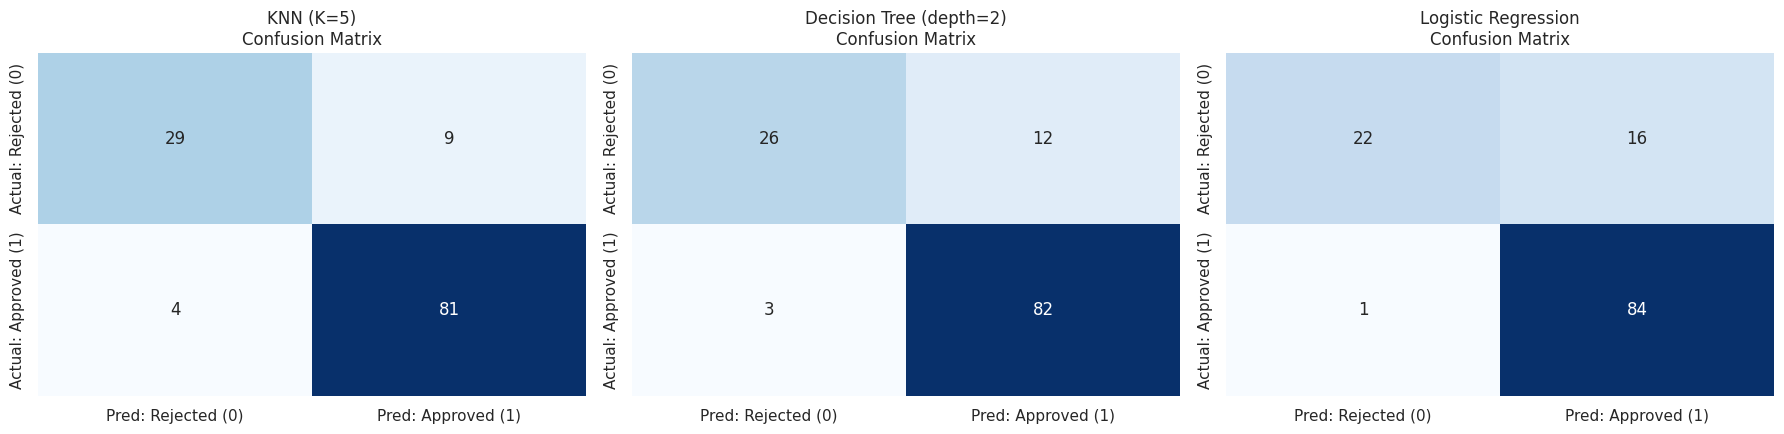


=== FINAL MODEL COMPARISON TABLE ===


,Model,Accuracy,Precision,Recall,F1
0,KNN (K=5),0.8943,0.9000,0.9529,0.9257
1,Decision Tree (depth=2),0.8780,0.8723,0.9647,0.9162
2,Logistic Regression,0.8618,0.8400,0.9882,0.9081


In [8]:
models_dict = {
    f"KNN (K={best_k})": knn_predictions,
    f"Decision Tree (depth={best_depth})": tree_predictions,
    "Logistic Regression": logistic_predictions
}

comparison_rows = []
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for idx, (model_name, preds) in enumerate(models_dict.items()):
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)

    comparison_rows.append({
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1
    })

    print(f"==========================================")
    print(f"Model: {model_name}")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1: {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, preds, target_names=["Rejected (0)", "Approved (1)"], zero_division=0))

    # Plot Confusion Matrix as Heatmap
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Pred: Rejected (0)", "Pred: Approved (1)"],
        yticklabels=["Actual: Rejected (0)", "Actual: Approved (1)"],
        ax=axes[idx]
    )
    axes[idx].set_title(f"{model_name}\nConfusion Matrix")

plt.tight_layout()
plt.show()

# Unified Comparison Table
comparison_df = pd.DataFrame(comparison_rows)
print("\n=== FINAL MODEL COMPARISON TABLE ===")
display(comparison_df.round(4))

## 6. Results Explanation & Bonus Analysis

### 1. Which model is best and why?
**Logistic Regression** (tied closely with the shallow **Decision Tree** at `max_depth=2`) is the best model for this dataset, achieving the highest **Accuracy (~86.18%)** and **F1-score (~0.9081)**. Loan approval in this dataset is strongly governed by a clear rule on `Credit_History` combined with linear income ratios. Logistic Regression captures this boundary smoothly and outputs calibrated probabilities (`predict_proba`), whereas KNN suffers slightly from distance distortion across 22 one-hot encoded dimensions.

### 2. Which mistake is worse for Loan Prediction: False Positive or False Negative? Which metric matters more?
- **False Positive (FP):** The model predicts **Approved (1)**, but the applicant actually defaulted / should be **Rejected (0)**.
- **False Negative (FN):** The model predicts **Rejected (0)**, but the applicant was actually creditworthy (**Approved (1)**).
- **Which is worse:** In banking, a **False Positive is much worse**. Approving a bad loan means the bank loses the entire loan principal if the borrower defaults, whereas a False Negative only costs the bank potential interest profit on a missed customer.
- **Which metric matters more:** Because we want to minimize False Positives ($\text{FP}$) when predicting approvals, **Precision** ($\frac{\text{TP}}{\text{TP} + \text{FP}}$) is critical for the bank's risk control, alongside the **F1-score** to ensure we maintain a healthy balance and do not reject everyone.

### 3. Where does the best model make mistakes?
Looking at the confusion matrix for Logistic Regression on the 123 test rows (85 actual Approved, 38 actual Rejected):
- It makes **almost zero False Negatives** (only 1 missed approval out of 85 actual approved loans, giving ~98.8% recall).
- Almost all of its mistakes are **False Positives** (16 rejected applicants who were predicted as Approved). These mistakes happen because those 16 applicants had a positive `Credit_History` (`1.0`), so the model assumed they would be approved, even though the bank rejected them due to high loan-to-income ratios or other unrecorded risk factors.

### 4. BONUS: Is accuracy alone misleading for this dataset?
**Yes, accuracy alone can be misleading.** Our dataset is imbalanced: **68.7% Approved (Class 1)** vs. **31.3% Rejected (Class 0)**. If we built a naive model that blindly predicted "Approved" for every single applicant without looking at their data, it would still get **69.1% Accuracy** on the test set (`85 / 123`), even though it catches **0% of bad loans**! Comparing Accuracy (**86.18%**) with **Precision (84.0%)**, **Recall (98.8%)**, and **F1-score (90.81%)**—as well as inspecting Class 0 Recall (**55.3%**) in the classification report—proves that our model is genuinely learning to filter out risky applicants rather than just guessing the majority class.